# Six-security economic scenario laboratory

**10 years · 120 monthly projection steps · 1,000 scenarios · exactly six securities.**

Thai and US equities, government bonds and representative corporate bonds.
The default uses a cached **31 October 2025** market snapshot. There are no
insurance liabilities or insurance cash-flow models.

Use **Restart Kernel → Run All** after opening this updated notebook. The main
plots and tables are ordinary notebook outputs, so they remain visible without
the widget renderer. Controls are optional and rerun only when their button is pressed.
An [HTML reading copy](outputs/six_securities.html) is provided for stable rendering.

Sections: **market data and actual points → six-security projection → martingale
test → Heston methods → mean convergence → timestep check → export**.

These are domestic THB risk-neutral scenarios, not forecasts of realized investment
returns. Observed curves/spots are distinct from assumed dynamics and credit inputs.

**Workflow:** edit settings below → run projection → inspect the visual checks.
Model formulas live in `models/`; inputs live in `data/`; generated files go to `outputs/`.


## VS Code: open this notebook and Run All

Select **Six Securities (.venv)** or this project's `.venv/bin/python` kernel, then
**Restart Kernel → Run All**. The existing environment is ready. To recreate it,
run these commands in the VS Code terminal from the project folder:

```sh
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
.venv/bin/python -m ipykernel install --sys-prefix --name six-securities --display-name "Six Securities (.venv)"
```

Install the VS Code **Python** and **Jupyter** extensions if needed. There is no
package build, native compiler, CLI, separate test runner or online data-fetch step.
The dated inputs and their limitations are documented in [data/sources.md](data/sources.md).
All experiments and visual checks are defined in this notebook, next to their figures.


In [1]:
from pathlib import Path
import os,sys,time,json,tempfile
from dataclasses import replace,asdict
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'models/simulation.py').exists()),None)
if ROOT is None:raise RuntimeError('Open the ESG_draft project folder in VS Code.')
OUT=ROOT/'outputs'
OUT.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'six-securities-matplotlib'))
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display,Markdown,HTML,clear_output
from scipy.stats import t as student_t
from models.market import load_market
from models.simulation import simulate
from models.equity import METHODS, simulate_heston, heston_prices
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from dataclasses import is_dataclass
import hashlib, importlib.metadata, platform
%matplotlib inline
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                     'grid.alpha':.18,'font.size':10,'figure.dpi':110})
pd.set_option('display.max_rows',18)
pd.set_option('display.max_columns',10)
pd.set_option('display.precision',6)

def table(frame):
    # Plain HTML tables, no dataframe-widget or CSS-version dependency.
    display(HTML('<div style="overflow-x:auto;max-width:100%">'+frame.to_html(index=False,border=0)+'</div>'))

def show(fig,name):
    fig.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)

LABELS=("TH equity (SET proxy)","US equity (S&P 500 proxy)",
        "TH government (10Y zero)","US government (10Y zero)",
        "TH corporate (10Y representative)","US corporate (10Y representative)")
COLORS=("#2463a5","#bd671c")


def json_default(value):
    if is_dataclass(value): return asdict(value)
    if isinstance(value,np.ndarray): return value.tolist()
    if isinstance(value,np.generic): return value.item()
    raise TypeError(str(type(value)))


def write_json(path,data):
    from pathlib import Path
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(data,default=json_default,indent=2,allow_nan=False)+"\n")


def metadata(market,settings):
    import QuantLib as ql
    raw = json.dumps(asdict(market),sort_keys=True,default=json_default)
    return {"market":asdict(market),"market_sha256":hashlib.sha256(raw.encode()).hexdigest(),
            "measure":"domestic risk-neutral Q("+market.domestic+")",
            "warning":"Observed curves/spots; assumed dynamics and credit",
            "settings":settings,"software":{name:importlib.metadata.version(name) for name in ("numpy","scipy","QuantLib","matplotlib","pandas")},
            "python":sys.version,"platform":platform.platform(),"precision":"float64",
            "driver_order":market.drivers}

OBSERVED,DATA=load_market()
print('Interpreter:',sys.executable)
print('Snapshot:',DATA['manifest']['snapshot_date'],'| THB domestic / USD foreign | unweighted pseudo-MC')
table(pd.Series(metadata(OBSERVED,{'notebook':True})['software'],name='version').rename_axis('package').reset_index())

Matplotlib is building the font cache; this may take a moment.


Interpreter: /Users/yh/ESG_draft/.venv/bin/python
Snapshot: 2025-10-31 | THB domestic / USD foreign | unweighted pseudo-MC


package,version
numpy,1.26.4
scipy,1.13.1
QuantLib,1.40
matplotlib,3.9.4
pandas,2.2.3


## 1. Real data: what is observed and what remains assumed?

The snapshot contains **54 ThaiBMA published zero-curve points**, **30 Federal
Reserve GSW zero-curve points**, Thai government dealer quotations, US Treasury
par-yield observations, and actual SET/S&P 500 index levels.

ThaiBMA zero nodes are already bootstrapped/interpolated by their publisher; GSW
nodes are a fitted staff research curve. They are **not raw traded zero bonds**.
The raw dealer/par quotations are shown separately because coupon-bond YTM,
par yield and zero rate are different quantities.

Thai zero rates are converted as annual effective rates. This convention is
**inferred and numerically cross-checked** from the simultaneous short-tenor BEY
quotes: $(1+y_{BEY}/2)^2-1$. US SVENY rates are continuously compounded as specified
in the source CSV. We interpolate **log discount factors**, with no additional
smoothing. Below the first US 1-year zero node, a flat zero rate is an explicit assumption.

Index spots initialize the equity proxies. No option surface or SET daily history
was loaded, so Heston parameters are **assumptions**, not real-data Heston calibration.
Corporate credit, rate volatility, FX and correlations also remain assumptions.
The SET report's trailing dividend ratio is used as a constant model dividend
assumption; it is not a forward implied dividend curve.

Sources: [ThaiBMA zero data](https://www.thaibma.or.th/yieldcurve/zero/2025-10-31),
[Fed GSW](https://www.federalreserve.gov/data/nominal-yield-curve.htm),
[US Treasury](https://home.treasury.gov/treasury-daily-interest-rate-xml-feed),
[SET report](https://www.set.or.th/en/market/news-and-alert/newsdetails?id=99380000&symbol=SET),
[S&P 500 cross-check in FRED](https://fred.stlouisfed.org/data/SP500).

In [2]:
provenance_rows=[]
for source in DATA['curves']:
    provenance_rows.append({'input':source['source'],'as_of':source['date'],'observations':len(source['nodes']),'status':'Published curve nodes; converted to discounts'})
for obs in DATA['indices']['observations']:
    provenance_rows.append({'input':obs['symbol']+' index spot','as_of':DATA['indices']['date'],'observations':obs['close'],'status':obs['source']})
provenance_rows.append({'input':'Corporate credit, stochastic dynamics, FX, correlations','as_of':'Assumed','observations':'See parameter table','status':'Not fitted to real option/corporate prices'})
table(pd.DataFrame(provenance_rows))
table(pd.DataFrame(DATA['curves'][0]['convention_checks']))
CURVE_POINTS=pd.concat([pd.DataFrame(source['nodes']).assign(currency=ccy) for source,ccy in zip(DATA['curves'],['THB','USD'])],ignore_index=True)
CURVE_POINTS.to_csv(OUT/'published-curve-points.csv',index=False)
table(CURVE_POINTS.groupby('currency',sort=False).head(8))

input,as_of,observations,status
ThaiBMA published bootstrapped zero curve (not individual bond quotes),2025-10-31,54,Published curve nodes; converted to discounts
Federal Reserve GSW fitted Treasury zero curve (staff research product),2025-10-31,30,Published curve nodes; converted to discounts
SET index spot,2025-10-31,1309.5,Stock Exchange of Thailand October 2025 market report
SP500 index spot,2025-10-31,6840.2,"Yahoo Finance daily index observations, cross-checked against FRED/SEC publication"
"Corporate credit, stochastic dynamics, FX, correlations",Assumed,See parameter table,Not fitted to real option/corporate prices


maturity,published_zero_pct,annual_effective_from_BEY_pct,difference_pct
0.076712,1.268081,1.268081,2.164615e-07
0.249315,1.268809,1.268808,6.454838e-07
0.498630,1.265043,1.265042,1.281359e-06
1.000000,1.262778,1.262778,4.556954e-07


maturity,published_yield_pct,zero_cc,currency
0.076712,1.268081,0.012601,THB
0.249315,1.268809,0.012608,THB
0.498630,1.265043,0.012571,THB
1.000000,1.262778,0.012549,THB
2.000000,1.333929,0.013251,THB
3.000000,1.364895,0.013557,THB
4.000000,1.405890,0.013961,THB
5.000000,1.468813,0.014581,THB
1.000000,3.689000,0.036890,USD
2.000000,3.583300,0.035833,USD


### Data markers on every curve

Circles mark published zero nodes (after compounding conversion); thin lines are
the model's interpolation. Discount-factor circles are the discounts implied by
those nodes, not additional market observations. The separate quotation plot
shows raw Thai dealer bond YTMs and the Treasury's published par observations.
They are not forced onto a zero-rate curve as if they were the same instrument.

In [3]:
# Plot/check helpers for this section (expand to inspect).
def curve_figures(market,data):
    figures={}
    for kind in ("zero","discount"):
        fig,axes=plt.subplots(1,2,figsize=(11.5,3.6),layout="constrained")
        for c,(source,ax) in enumerate(zip(data["curves"],axes)):
            nodes=source["nodes"]
            maturity=np.array([r["maturity"] for r in nodes]);zero=np.array([r["zero_cc"] for r in nodes])
            keep=maturity<=30
            grid=np.linspace(.03,30,500)
            if kind=="zero":
                ax.plot(grid,-100*market.curves[c].log_discount(grid)/grid,color=COLORS[c],label="Model interpolation")
                ax.scatter(maturity[keep],100*zero[keep],s=25,facecolor="white",edgecolor=COLORS[c],zorder=5,label="Published zero nodes (converted)")
                ax.set(ylabel="Continuous zero rate (%)")
            else:
                ax.plot(grid,market.curves[c].discount(grid),color=COLORS[c],label="Log-linear discount interpolation")
                ax.scatter(maturity[keep],np.exp(-zero[keep]*maturity[keep]),s=25,facecolor="white",edgecolor=COLORS[c],zorder=5,label="Discounts at published zero nodes")
                ax.set(ylabel="P(0,T)")
            ax.set(title=("ThaiBMA" if c==0 else "Fed GSW")+" | "+source["date"],xlabel="Maturity (years)",xlim=(0,30))
            ax.legend(fontsize=8,loc="best")
        figures[kind]=fig
    fig,axes=plt.subplots(1,2,figsize=(11.5,3.5),layout="constrained")
    thai=data["curves"][0]["government_dealer_quotes"]
    actual=[r for r in thai if not r["synthetic_quote"] and r["maturity"]<=30]
    axes[0].scatter([r["maturity"] for r in actual],[r["yield_pct"] for r in actual],s=20,color=COLORS[0],label="Individual dealer-quoted bond YTMs")
    us=data["us_par"]["nodes"]
    axes[1].scatter([r["maturity"] for r in us],[r["yield_pct"] for r in us],s=26,color=COLORS[1],label="Treasury published par-yield points")
    for c,ax in enumerate(axes):
        ax.set(title=("Thai government dealer quotations" if c==0 else "U.S. Treasury par observations"),xlabel="Maturity (years)",ylabel="Published yield (%)")
        ax.legend(fontsize=8)
    figures["government_observations"]=fig
    return figures

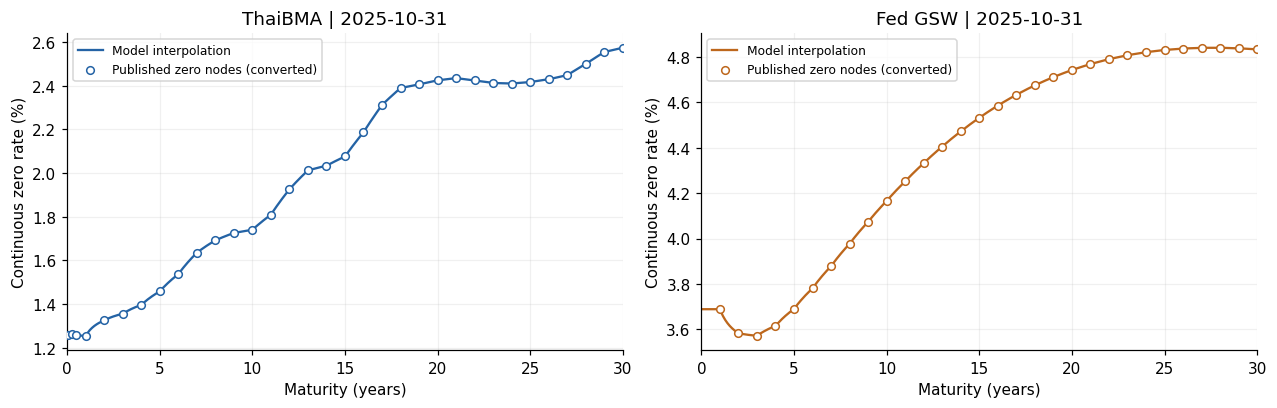

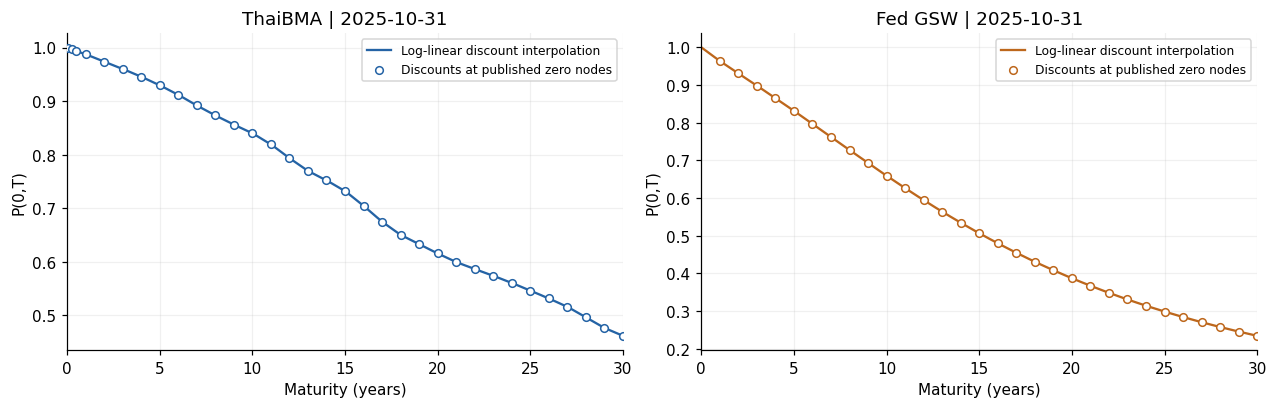

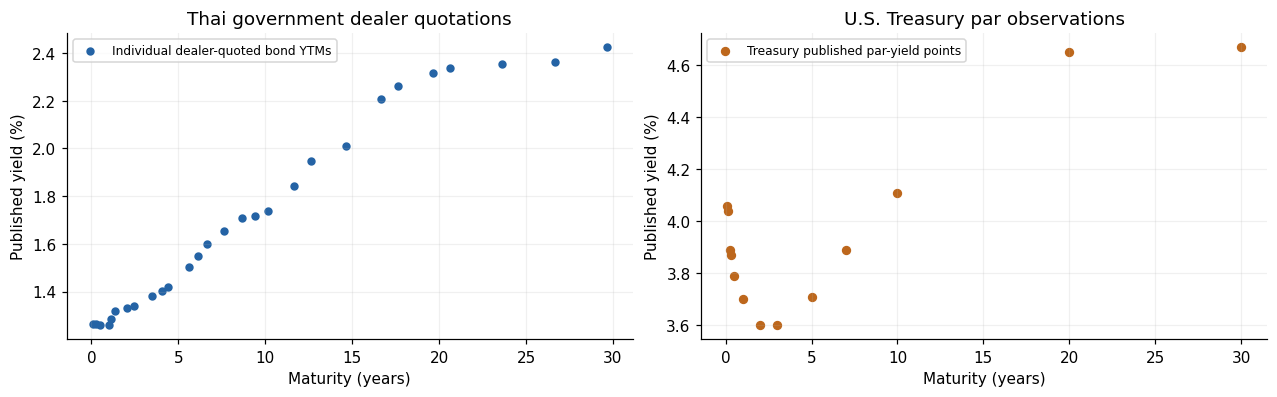

In [4]:
for name,fig in curve_figures(OBSERVED,DATA).items():
    show(fig,'curve-'+name)

## 2. Monthly projection: six securities, 1,000 scenarios, 10 years

The governments are 10-year zero-coupon claims; the corporates are representative
10-year, 4.5% annual coupon bonds with 40% recovery of par. They are **not named
traded corporate issues**. The two equity proxies start at the observed SET and
S&P 500 levels. FX is a conversion state, not a seventh security.

Only security dividends, coupons, principal and recovery are included. At year
ten the bonds' **ex-distribution** prices fall to zero after redemption; their
cumulative gains retain the payment. There are no insurance liabilities.

Default output shape is **121 dates × 1,000 paths × 6 securities**, including date
zero. Internal steps are monthly by default. The final timestep comparison refines the internal grid while
retaining monthly reporting. Curve interpolation knots are not treated as payment dates.

In [5]:
# Plot/check helpers for this section (expand to inspect).
def security_paths_figure(paths):
    if paths.values is None:raise ValueError("Run with store_security_values=True")
    fig,axes=plt.subplots(3,2,figsize=(11.5,9),layout="constrained")
    initial=paths.values[0]
    for a,ax in enumerate(axes.flat):
        level=100*paths.values[:,:,a]/initial[:,a]
        q=np.quantile(level,[.05,.5,.95],axis=1)
        ax.plot(paths.times,level[:,:12],alpha=.16,linewidth=.7,color=COLORS[a%2])
        ax.fill_between(paths.times,q[0],q[2],alpha=.15,color=COLORS[a%2])
        ax.plot(paths.times,q[1],linewidth=2,color=COLORS[a%2],label="Median + 5–95% scenario range")
        ax.set(title=LABELS[a],xlabel="Projection year",ylabel="Ex-distribution value (initial = 100)",xlim=(0,paths.times[-1]))
    fig.suptitle(f"Exactly six securities | {paths.states.shape[1]:,} scenarios | monthly reporting",fontsize=13)
    return fig


def martingale_figure(paths):
    fig,axes=plt.subplots(3,2,figsize=(11.5,9),layout="constrained")
    normalized=paths.gains/paths.gains[0]
    mean=normalized.mean(axis=1);se=normalized.std(axis=1,ddof=1)/np.sqrt(normalized.shape[1])
    for a,ax in enumerate(axes.flat):
        ax.axhline(1,color="#b23b36",linestyle="--",linewidth=1.4,label="Martingale target = 1")
        ax.fill_between(paths.times,mean[:,a]-1.96*se[:,a],mean[:,a]+1.96*se[:,a],color=COLORS[a%2],alpha=.2,label="Pointwise 95% MC sampling interval")
        ax.plot(paths.times,mean[:,a],color=COLORS[a%2],linewidth=1.8,label="Mean discounted cumulative gain")
        ax.set(title=LABELS[a],xlabel="Projection year",ylabel="Mean of G(t) / G(0)",xlim=(0,paths.times[-1]))
        if a==0:ax.legend(fontsize=7.5,loc="best")
    fig.suptitle("Martingale test: the mean should stay at 1, including security distributions",fontsize=12)
    return fig

In [6]:
# MAIN SETTINGS: 10 years / 120 months; monthly reporting always remains monthly.
N_SCENARIOS = 1000
YEARS = 10.
SEED = 7
RUN = {}
model_control=widgets.Dropdown(options=[('G2++','g2'),('Hull–White','hw')],value='g2',description='Rates')
method_control=widgets.Dropdown(options=[('Full truncation','full_truncation'),('Reflection','reflection')],description='Heston')
paths_control=widgets.Dropdown(options=[500,1000,2000],value=N_SCENARIOS,description='Scenarios')
seed_control=widgets.BoundedIntText(value=SEED,min=0,max=2**31-1,description='Seed')
run_button=widgets.Button(description='Run six securities',button_style='primary',icon='play')
live_output=widgets.Output()

def run_projection(_=None,render=True):
    run_button.disabled=True
    try:
        settings=dict(paths=paths_control.value,horizon=YEARS,seed=seed_control.value,
                      internal_steps=12,heston_scheme=method_control.value)
        market,_=load_market(model=model_control.value)
        start=time.perf_counter()
        p=simulate(market,**settings)
        RUN.clear()
        RUN.update(paths=p,market=market,settings=settings,source='observed',model=model_control.value,
                   seconds=time.perf_counter()-start)
        with live_output:
            clear_output(wait=True)
            print('ACTIVE:',RUN['model'],settings,'| shape',p.gains.shape,'|',round(RUN['seconds'],2),'seconds')
            if render:
                show(security_paths_figure(p),'live-security-paths')
                show(martingale_figure(p),'live-martingale')
                print('Button updates these two plots. Rerun subsequent sections to update their saved results.')
    except Exception as error:
        with live_output:
            print(type(error).__name__+': '+str(error))
            print('Settings rejected. Results retain their last successful configuration.')
        if not render:
            raise
    finally:
        run_button.disabled=False

run_button.on_click(run_projection)
display(widgets.VBox([widgets.HBox([model_control,method_control]),
                     widgets.HBox([paths_control,seed_control]),run_button,live_output]))
run_projection(render=False)
print('Projection:',RUN['paths'].gains.shape,'(dates, scenarios, securities)')


Projection: (121, 1000, 6) (dates, scenarios, securities)


Ordinary saved snapshot: observed g2 {'paths': 1000, 'horizon': 10.0, 'seed': 7, 'internal_steps': 12, 'heston_scheme': 'full_truncation'}


security,model_asset_name,initial_THB_value
TH equity (SET proxy),equity_local,1309.500000
US equity (S&P 500 proxy),equity_foreign,239407.000000
TH government (10Y zero),government_local,0.840298
US government (10Y zero),government_foreign,23.076806
TH corporate (10Y representative),corporate_local,114.341185
US corporate (10Y representative),corporate_foreign,3301.411027


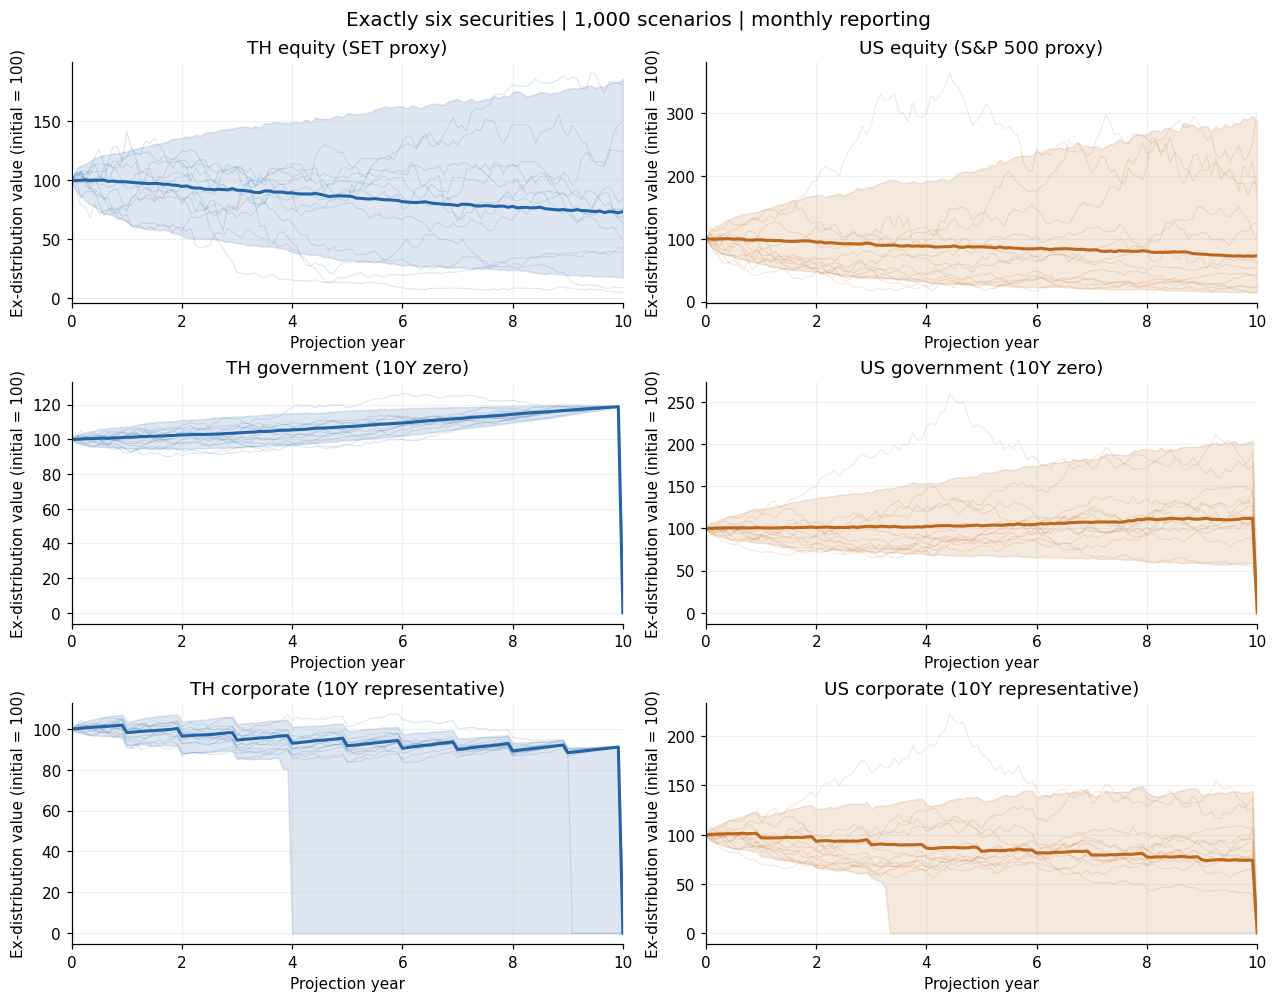

Bond prices reach zero after redemption at year ten; this is expected for ex-distribution values.


In [7]:
print('Ordinary saved snapshot:',RUN['source'],RUN['model'],RUN['settings'])
p=RUN['paths']
table(pd.DataFrame({'security':LABELS,'model_asset_name':p.names,'initial_THB_value':p.values[0].mean(axis=0)}))
show(security_paths_figure(p),'six-security-paths')
print('Bond prices reach zero after redemption at year ten; this is expected for ex-distribution values.')

## 3. Martingale test — the mean should remain at ONE

For each path, let $D_t$ be its domestic discount factor, $V_t$ the security's
THB ex-distribution value, and $C_u$ its THB dividends/coupons/redemption/recovery:

$$M_t=\frac{G_t}{G_0},\qquad G_t=D_tV_t+\sum_{u\le t}D_uC_u,
\qquad \mathbb{E}[M_t]=1.$$

Every panel below has a **red target line at 1**, the sample mean, and a pointwise
95% Monte Carlo sampling interval. These bands describe uncertainty in the mean;
they are not 5–95% scenario percentiles. A raw stock price or ex-coupon bond price
alone is not the martingale quantity. Foreign distributions use contemporaneous FX.

The test is unconditional. It does not prove conditional martingality. With six
assets and many dates, some confidence-band crossings can occur by chance;
persistent drift across seeds, path counts and smaller steps needs investigation.

In [8]:
# Plot/check helpers for this section (expand to inspect).
def gain_diagnostics(paths):
    """Terminal discounted gain change / initial value, with pseudo-MC IID SE only.

    Review flags are exploratory, instrument-wise 3-SE checks. Neither a pass
    nor a finite set of unconditional means establishes conditional martingality.
    """
    n = paths.gains.shape[1]
    initial = paths.gains[0].mean(axis=0)
    if np.any(np.abs(initial)<1e-12):
        raise ValueError("Relative gains require nonzero initial values")
    change = (paths.gains[-1]-paths.gains[0])/initial
    means = change.mean(axis=0)
    iid = n>=2
    errors = change.std(axis=0,ddof=1)/np.sqrt(n) if iid else np.full(len(initial),np.nan)
    rows = []
    for name,level,mean,se in zip(paths.names,initial,means,errors):
        if not iid:
            z,status = None,"at least two paths required"
        elif se<1e-14:
            z,status = None,("zero sampling variation; no drift" if abs(mean)<1e-12 else "REVIEW: drift without sampling variation")
        else:
            z = float(mean/se)
            status = "inside 3 SE" if abs(z)<=3 else "REVIEW: outside 3 SE"
        rows.append({"asset":name,"initial_domestic_value":float(level),"relative_gain_change":float(mean),
                     "standard_error":float(se) if iid else None,"z_score":z,"sampling_check":status})
    return rows



def terminal_test_figure(paths):
    x=paths.gains[-1]/paths.gains[0]
    mean=x.mean(axis=0)-1;se=x.std(axis=0,ddof=1)/np.sqrt(len(x))
    fig,ax=plt.subplots(figsize=(10,4),layout="constrained")
    ax.axvline(0,color="#b23b36",linestyle="--",label="Target: zero drift")
    ax.errorbar(mean*100,np.arange(6),xerr=1.96*se*100,fmt="o",capsize=4,color="#2463a5",label="Mean drift ± 1.96 MC SE")
    ax.set(yticks=range(6),yticklabels=LABELS,xlabel="Terminal mean discounted gain change (%)",title="Ten-year terminal check — sampling intervals, not scenario percentiles")
    ax.invert_yaxis();ax.legend(fontsize=8)
    return fig

Gain-accounting identity: maximum absolute difference = 1.1641532182693481e-10


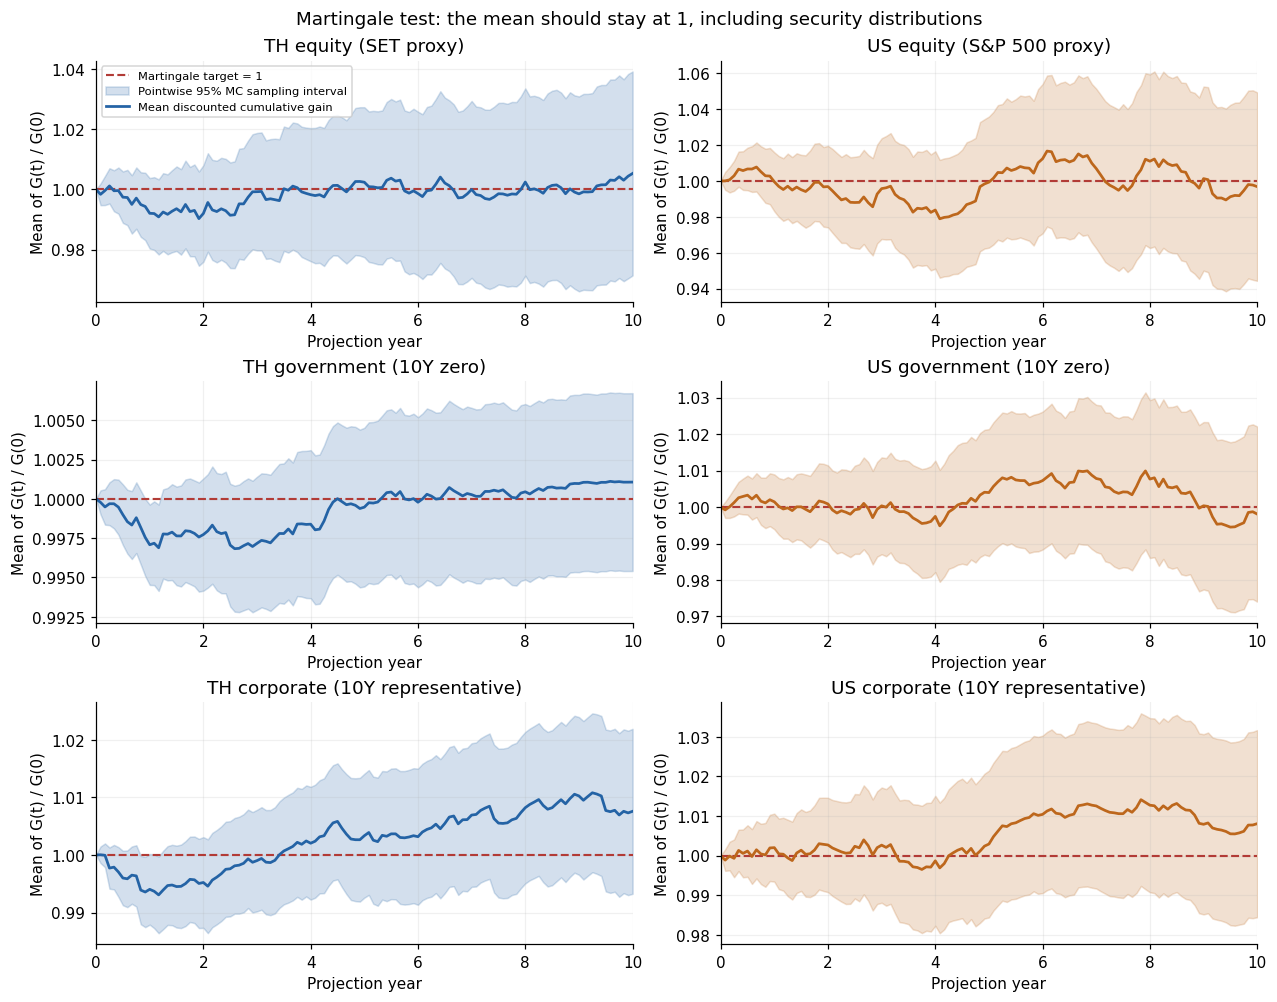

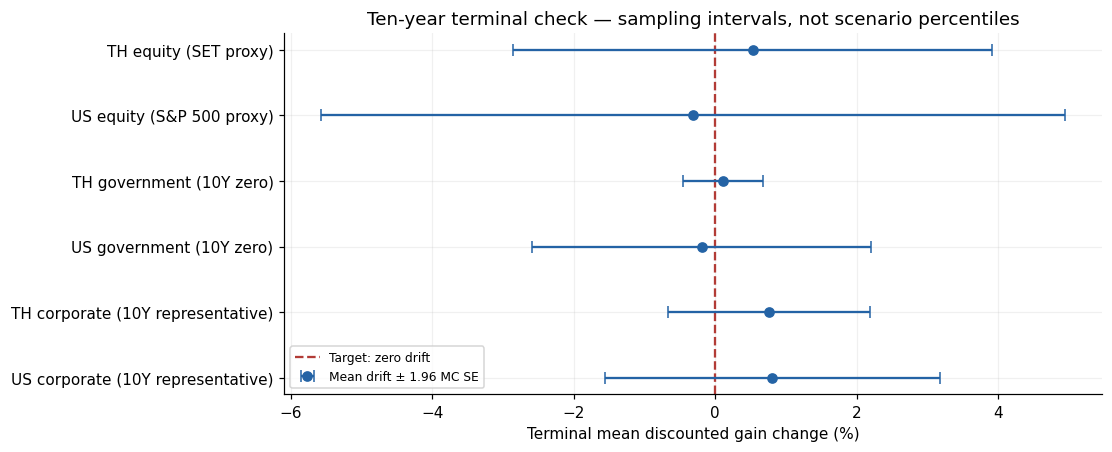

security,mean_M10,standard_error,CI95_low,CI95_high,z_score,sampling_check
TH equity (SET proxy),1.005270,0.017268,0.971424,1.039116,0.305201,inside 3 SE
US equity (S&P 500 proxy),0.996853,0.026804,0.944317,1.049390,-0.117392,inside 3 SE
TH government (10Y zero),1.001065,0.002886,0.995408,1.006722,0.369038,inside 3 SE
US government (10Y zero),0.998072,0.012243,0.974076,1.022069,-0.157454,inside 3 SE
TH corporate (10Y representative),1.007572,0.007297,0.993269,1.021875,1.037691,inside 3 SE
US corporate (10Y representative),1.008071,0.012057,0.984439,1.031704,0.669390,inside 3 SE


In [9]:
p=RUN['paths']
identity_error=np.max(np.abs(p.gains-p.discounts[:,:,0,None]*p.values-p.discounted_distributions))
print('Gain-accounting identity: maximum absolute difference =',identity_error)
show(martingale_figure(p),'martingale-six-panels')
show(terminal_test_figure(p),'martingale-terminal')
terminal=pd.DataFrame(gain_diagnostics(p))
terminal.insert(0,'security',LABELS)
terminal['mean_M10']=1+terminal['relative_gain_change']
terminal['CI95_low']=terminal['mean_M10']-1.96*terminal['standard_error']
terminal['CI95_high']=terminal['mean_M10']+1.96*terminal['standard_error']
table(terminal[['security','mean_M10','standard_error','CI95_low','CI95_high','z_score','sampling_check']])
terminal.to_csv(OUT/'martingale-terminal.csv',index=False)

In [10]:
# Plot/check helpers for this section (expand to inspect).
def structural_checks(paths):
    """Mechanical checks, not a certificate of model/pricing accuracy."""
    names = paths.state_names
    nonnegative = [j for j,n in enumerate(names) if n.startswith(("v_","credit_"))]
    return {
        "finite states":bool(np.all(np.isfinite(paths.states))),
        "finite discounted gains":bool(np.all(np.isfinite(paths.gains))),
        "strictly positive finite discount factors":bool(np.all(np.isfinite(paths.discounts)) and np.all(paths.discounts>0)),
        "strictly positive finite FX":bool(np.all(np.isfinite(paths.fx)) and np.all(paths.fx>0)),
        "nonnegative reported variance and credit factors":bool(np.all(paths.states[:,:,nonnegative]>=0)),
        "strictly increasing reporting grid":bool(np.all(np.diff(paths.times)>0)),
        "default times are positive finite or +infinity":bool(np.all((paths.defaults>0) & ~np.isnan(paths.defaults))),
    }


def discount_checks(paths,market):
    """Domestic and FX-converted foreign unit-payoff prices, unweighted pseudo-MC."""
    t = float(paths.times[-1])
    samples = (paths.discounts[-1,:,0],paths.discounts[-1,:,0]*paths.fx[-1])
    references = (float(market.curves[0].discount(t)),float(market.fx_spot*market.curves[1].discount(t)))
    rows = []
    for name,values,reference in zip(("domestic unit payoff","foreign unit payoff converted at maturity"),samples,references):
        mean,se = float(values.mean()),float(values.std(ddof=1)/np.sqrt(len(values)))
        rows.append({"claim":name,"MC_domestic_price":mean,"curve_reference":reference,"MC_standard_error":se,
                     "difference":mean-reference,"inside_3_SE":bool(abs(mean-reference)<=3*se+1e-10)})
    return rows

In [11]:
checks=structural_checks(RUN['paths'])
table(pd.DataFrame({'visual_sanity_check':list(checks),'passed':list(checks.values())}))
table(pd.DataFrame(discount_checks(RUN['paths'],RUN['market'])))
print('Negative raw Euler updates [TH variance, US variance, TH credit, US credit]:',
      RUN['paths'].diagnostics['negative_raw_euler_counts'])
print('Raw Euler negatives can occur; pricing uses the documented nonnegative projection.')


visual_sanity_check,passed
finite states,True
finite discounted gains,True
strictly positive finite discount factors,True
strictly positive finite FX,True
nonnegative reported variance and credit factors,True
strictly increasing reporting grid,True
default times are positive finite or +infinity,True


claim,MC_domestic_price,curve_reference,MC_standard_error,difference,inside_3_SE
domestic unit payoff,0.841193,0.840298,0.002425,0.000895,True
foreign unit payoff converted at maturity,23.032321,23.076806,0.282529,-0.044485,True


Negative raw Euler updates [TH variance, US variance, TH credit, US credit]: [7289, 2731, 0, 0]
Raw Euler negatives can occur; pricing uses the documented nonnegative projection.


## 4. Heston simulation methods

| Method | Variance handling | Where this notebook uses it |
|---|---|---|
| Full-truncation Euler | Keep a raw Euler state; use its nonnegative part in drift/diffusion | Full correlated six-security projection and standalone comparison |
| Reflection Euler | Use the absolute raw state in drift/diffusion | Full correlated projection and standalone comparison |
| Quadratic exponential (QE) | Match CIR conditional variance moments with quadratic/exponential branches | Standalone constant-rate Heston comparison |
| QE-martingale | QE plus conditional exponential-moment correction for the log stock update | Standalone constant-rate Heston comparison |

The standalone step formulas follow the public QuantLib process. The option-price
comparison below checks them against its analytic Heston valuation. Its normals are independent inputs: correlation is
applied once within the Heston step. QE uses a different orthogonal construction
from Euler, so common supplied normals do not imply identical variance paths.

**QE is not silently inserted into the correlated rates/FX hybrid.** That requires
separate coupling and foreign-drift validation. Full truncation/reflection preserve
the existing hybrid driver construction. Positivity alone does not imply low pricing bias.

[QuantLib Heston process](https://github.com/lballabio/QuantLib/blob/master/ql/processes/hestonprocess.cpp)

In [12]:
# Plot/check helpers for this section (expand to inspect).
def heston_paths_figure(results):
    colors=plt.get_cmap("tab10").colors
    fig,axes=plt.subplots(1,2,figsize=(11.5,3.8),layout="constrained")
    for c,(method,p) in enumerate(results.items()):
        y=p.discounted_total_return;mean=y.mean(axis=1);se=y.std(axis=1,ddof=1)/np.sqrt(y.shape[1])
        axes[0].plot(p.times,mean,label=method,color=colors[c],linewidth=1.3)
        axes[0].fill_between(p.times,mean-1.96*se,mean+1.96*se,color=colors[c],alpha=.07)
        axes[1].hist(p.variances[-1],bins=60,density=True,histtype="step",label=method,color=colors[c])
    axes[0].axhline(1,color="#b23b36",linestyle="--")
    axes[0].set(title="Standalone Heston: normalized discounted total return",xlabel="Year",ylabel="Mean (target = 1)")
    axes[1].set(title="Terminal variance distributions",xlabel="Variance",ylabel="Density")
    axes[0].legend(fontsize=7.5);axes[1].legend(fontsize=7.5)
    return fig

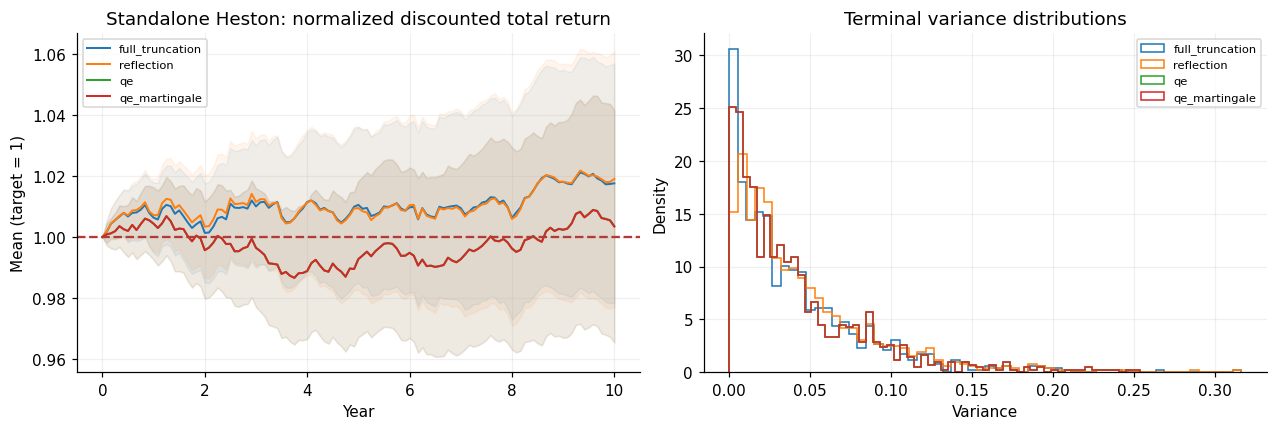

method,scenarios,months,terminal_mean_discounted_total_return,terminal_MC_SE,negative_raw_variance_updates
full_truncation,1000,120,1.017578,0.020009,7399
reflection,1000,120,1.019019,0.021334,4794
qe,1000,120,1.003533,0.019409,0
qe_martingale,1000,120,1.003432,0.019397,0


In [13]:
# Separate, constant-rate benchmark: spot rebased to 100, no stochastic rates/FX.
benchmark_params=replace(RUN['market'].equities[0],spot=100.)
HESTON_RUNS={method:simulate_heston(benchmark_params,paths=1000,horizon=10.,steps_per_year=12,
                                  seed=7,method=method,rate=.03) for method in METHODS}
show(heston_paths_figure(HESTON_RUNS),'heston-method-paths')
table(pd.DataFrame([{'method':method,'scenarios':1000,'months':120,
                    'terminal_mean_discounted_total_return':r.discounted_total_return[-1].mean(),
                    'terminal_MC_SE':r.discounted_total_return[-1].std(ddof=1)/np.sqrt(1000),
                    'negative_raw_variance_updates':r.negative_raw_updates} for method,r in HESTON_RUNS.items()]))

### One-year option pricing benchmark and step refinement

The next test fixes deterministic rates at 3%, spot and strike at 100, and compares
one-year call prices with **QuantLib's analytic Heston price**. This is a valid
limiting-case benchmark, not a claim that a stochastic-rate hybrid price must equal
a deterministic-rate formula. Each plotted point uses 1,000 paths per run and
eight independent runs; its interval is a Student-t interval across run means.

Sampling error and step bias are separate. Neither full truncation nor reflection
needs to converge monotonically in one noisy experiment. QE-martingale corrects
a discrete exponential moment; it does not make all derivative prices exact.

In [14]:
# Plot/check helpers for this section (expand to inspect).
def heston_comparison(params,paths=1000,replicates=8,frequencies=(12,52,104),seed=500):
    """One-year, constant-rate pricing test. Parameters are held fixed,
    with independent MC replicates and common supplied
    independent normals across methods at a fixed grid.
    """
    from dataclasses import replace
    p=replace(params,spot=100.)
    reference=float(heston_prices(p,[{"strike":100.,"maturity":1.}],rate=.03)[0])
    rows=[]
    for frequency in frequencies:
        for method in METHODS:
            estimates=[]
            for r in range(replicates):
                sample=simulate_heston(p,paths=paths,horizon=1.,steps_per_year=frequency,
                        seed=seed+r*101,method=method,keep_paths=False)
                estimates.append(sample.call_payoffs.mean())
            values=np.array(estimates)
            rows.append({"method":method,"steps_per_year":frequency,"paths_per_run":paths,"replicates":replicates,
                         "MC_price":float(values.mean()),"QuantLib_reference":reference,
                         "pricing_error":float(values.mean()-reference),
                         "replicate_SE":float(values.std(ddof=1)/np.sqrt(replicates))})
    return rows



def heston_pricing_figure(rows):
    methods=list(dict.fromkeys(r['method'] for r in rows));colors=plt.get_cmap("tab10").colors
    fig,ax=plt.subplots(figsize=(10,4),layout="constrained")
    ax.axhline(0,color="#b23b36",linestyle="--",label="QuantLib analytic reference")
    for c,method in enumerate(methods):
        data=[r for r in rows if r['method']==method]
        radius=[student_t.ppf(.975,r['replicates']-1)*r['replicate_SE'] for r in data]
        ax.errorbar(np.arange(len(data))+(c-1.5)*.055,[r['pricing_error'] for r in data],yerr=radius,
                    fmt="o-",capsize=3,color=colors[c],label=method)
    ax.set(xticks=range(len(data)),xticklabels=[str(r['steps_per_year']) for r in data],xlabel="Nominal internal steps/year",
           ylabel="MC call price − analytic Heston price",title="One-year call: scheme bias and replicate uncertainty (spot = 100)")
    ax.legend(fontsize=8,ncol=2)
    return fig

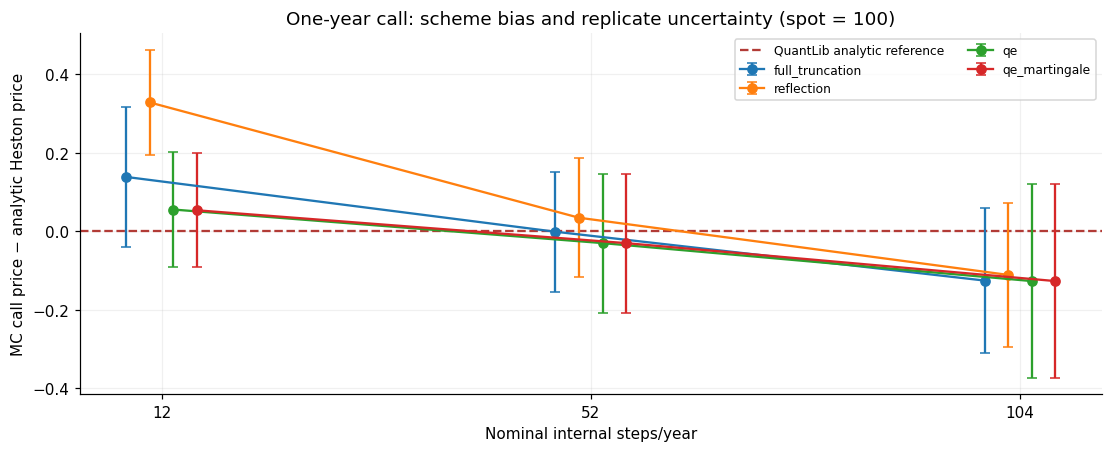

method,steps_per_year,paths_per_run,replicates,MC_price,QuantLib_reference,pricing_error,replicate_SE
full_truncation,12,1000,8,6.917168,6.778445,0.138723,0.075397
reflection,12,1000,8,7.106857,6.778445,0.328412,0.056752
qe,12,1000,8,6.834127,6.778445,0.055683,0.061509
qe_martingale,12,1000,8,6.832220,6.778445,0.053775,0.061497
full_truncation,52,1000,8,6.777601,6.778445,-0.000843,0.064432
reflection,52,1000,8,6.813268,6.778445,0.034824,0.064084
qe,52,1000,8,6.748664,6.778445,-0.029781,0.074785
qe_martingale,52,1000,8,6.748549,6.778445,-0.029896,0.074783
full_truncation,104,1000,8,6.653262,6.778445,-0.125182,0.077885
reflection,104,1000,8,6.667653,6.778445,-0.110792,0.077947


In [15]:
HESTON_PRICES=heston_comparison(benchmark_params,paths=1000,replicates=8,frequencies=(12,52,104))
show(heston_pricing_figure(HESTON_PRICES),'heston-method-pricing')
table(pd.DataFrame(HESTON_PRICES))

## 5. Convergence of the sample mean: error scales as N to the minus one-half

The normalized **mean level** should approach 1. Its **sampling standard error**
should decrease as

$$SE(\bar M_N)=\frac{\sigma_M}{\sqrt N}\propto N^{-1/2}.$$

This is $1/\sqrt{N}$ (not $1/N^{-1/2}$). Doubling $N$ reduces sampling error by
about $\sqrt{2}$; reducing it by half requires about four times as many paths.

The default projection still has 1,000 scenarios. The **separate convergence
experiment** compares 125, 250, 500, 1,000, 2,000 and 4,000 scenarios per run across
16 independent simulations of the same ten-year monthly model. It plots:

- RMSE of the terminal mean relative to the martingale target 1;
- the measured standard deviation of independent run means;
- an $N^{-1/2}$ sampling guide, scaled by the pooled terminal-path standard deviation.

The $N$ values use nested prefixes inside each independent run. Slopes are
descriptive, not independent-regression confidence estimates. Scheme bias does
not vanish with more paths, so RMSE can flatten at a bias floor, particularly for
default/recovery approximations. Rare defaults can also make small samples irregular.

In [16]:
# Plot/check helpers for this section (expand to inspect).
def mean_convergence(market,sizes=(125,250,500,1000,2000,4000),replicates=16,horizon=10.,seed=1009,heston_scheme="full_truncation"):
    """Sampling error of terminal mean gains against known target one.

    Each replicate is an independent simulation. N values share nested prefixes
    inside a replicate, so the fitted log-log slope is descriptive, not an
    independent-regression confidence statement. Corporate scheme bias can remain.
    """
    sizes=np.array(sizes,dtype=int)
    if len(sizes)<2 or np.any(sizes<2) or np.any(np.diff(sizes)<=0) or replicates<2:
        raise ValueError("Increasing sample sizes >=2 and independent replicates >=2 required")
    estimates=[];iid_errors=[];pool=[]
    for r in range(replicates):
        p=simulate(market,paths=int(sizes[-1]),horizon=horizon,seed=seed+101*r,
                       store_security_values=False,terminal_only=True,heston_scheme=heston_scheme)
        normalized=p.gains[-1]/p.gains[0]
        means=[];se=[]
        for n in sizes:
            means.append(normalized[:n].mean(axis=0))
            se.append(normalized[:n].std(axis=0,ddof=1)/np.sqrt(n))
        estimates.append(means);iid_errors.append(se);pool.append(normalized)
    estimates=np.array(estimates)
    rmse=np.sqrt(np.mean((estimates-1.)**2,axis=0))
    empirical_sd=estimates.std(axis=0,ddof=1)
    measured_se=np.mean(iid_errors,axis=0)
    sigma=np.concatenate(pool).std(axis=0,ddof=1)
    theoretical=sigma[None,:]/np.sqrt(sizes[:,None])
    slopes=[float(np.polyfit(np.log(sizes),np.log(np.maximum(rmse[:,a],1e-15)),1)[0]) for a in range(len(p.names))]
    sample=pool[0]
    running=np.cumsum(sample,axis=0)/np.arange(1,len(sample)+1)[:,None]
    return {"asset_names":p.names,"sizes":sizes,"replicates":replicates,"horizon":horizon,"seed":seed,"replicate_seed_step":101,
            "rmse":rmse,"empirical_SD_of_means":empirical_sd,"average_IID_SE":measured_se,
            "sigma_over_sqrt_N":theoretical,"rmse_loglog_slopes":slopes,
            "replicate_means":estimates,"running_means_first_run":running,
            "large_N_average_drift":estimates[:,-1,:].mean(axis=0)-1.,
            "interpretation":"N^-1/2 is sampling error, not the mean itself; fixed-step bias and rare defaults can prevent RMSE from following that slope."}



def convergence_figure(result):
    fig,axes=plt.subplots(3,2,figsize=(11.5,9.5),layout="constrained")
    n=result['sizes']
    for a,ax in enumerate(axes.flat):
        ax.loglog(n,result['rmse'][:,a],"o-",color=COLORS[a%2],label="Observed RMSE vs target 1")
        ax.loglog(n,result['empirical_SD_of_means'][:,a],"s--",color="#38966a",label="SD of independent means")
        ax.loglog(n,result['sigma_over_sqrt_N'][:,a],":",color="#555555",linewidth=2,label=r"Sampling guide: $\sigma/\sqrt{N}$")
        ax.axvline(1000,color="#8b8b8b",alpha=.35)
        ax.xaxis.set_major_locator(FixedLocator(n))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value,position:f"{int(value):,}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set(title=LABELS[a]+f" | RMSE slope {result['rmse_loglog_slopes'][a]:.2f}",xlabel="Scenarios per independent run, N (log)",ylabel="Error of normalized mean (log)")
        if a==0:ax.legend(fontsize=7.2)
    fig.suptitle(f"Mean convergence across {result['replicates']} independent runs | ideal sampling slope = −0.5",fontsize=12)
    return fig


def running_means_figure(result):
    # Explicit margins avoid tight-layout clipping of long vertical labels and
    # the shared title when nbconvert/inline backends use different DPIs.
    fig,axes=plt.subplots(3,2,figsize=(11.5,9))
    fig.subplots_adjust(left=.09,right=.98,bottom=.07,top=.91,hspace=.52,wspace=.27)
    running=result['running_means_first_run'];n=np.arange(1,len(running)+1)
    for a,ax in enumerate(axes.flat):
        ax.axhline(1,color="#b23b36",linestyle="--")
        ax.plot(n[24:],running[24:,a],color=COLORS[a%2],linewidth=1)
        ax.axvline(1000,color="#777777",alpha=.4)
        ax.set(title=LABELS[a],xlabel="Number of included paths",ylabel=r"Running mean $G_T/G_0$")
    fig.suptitle("One running mean fluctuates; sampling error scales as 1/sqrt(N)",fontsize=12,y=.985)
    return fig

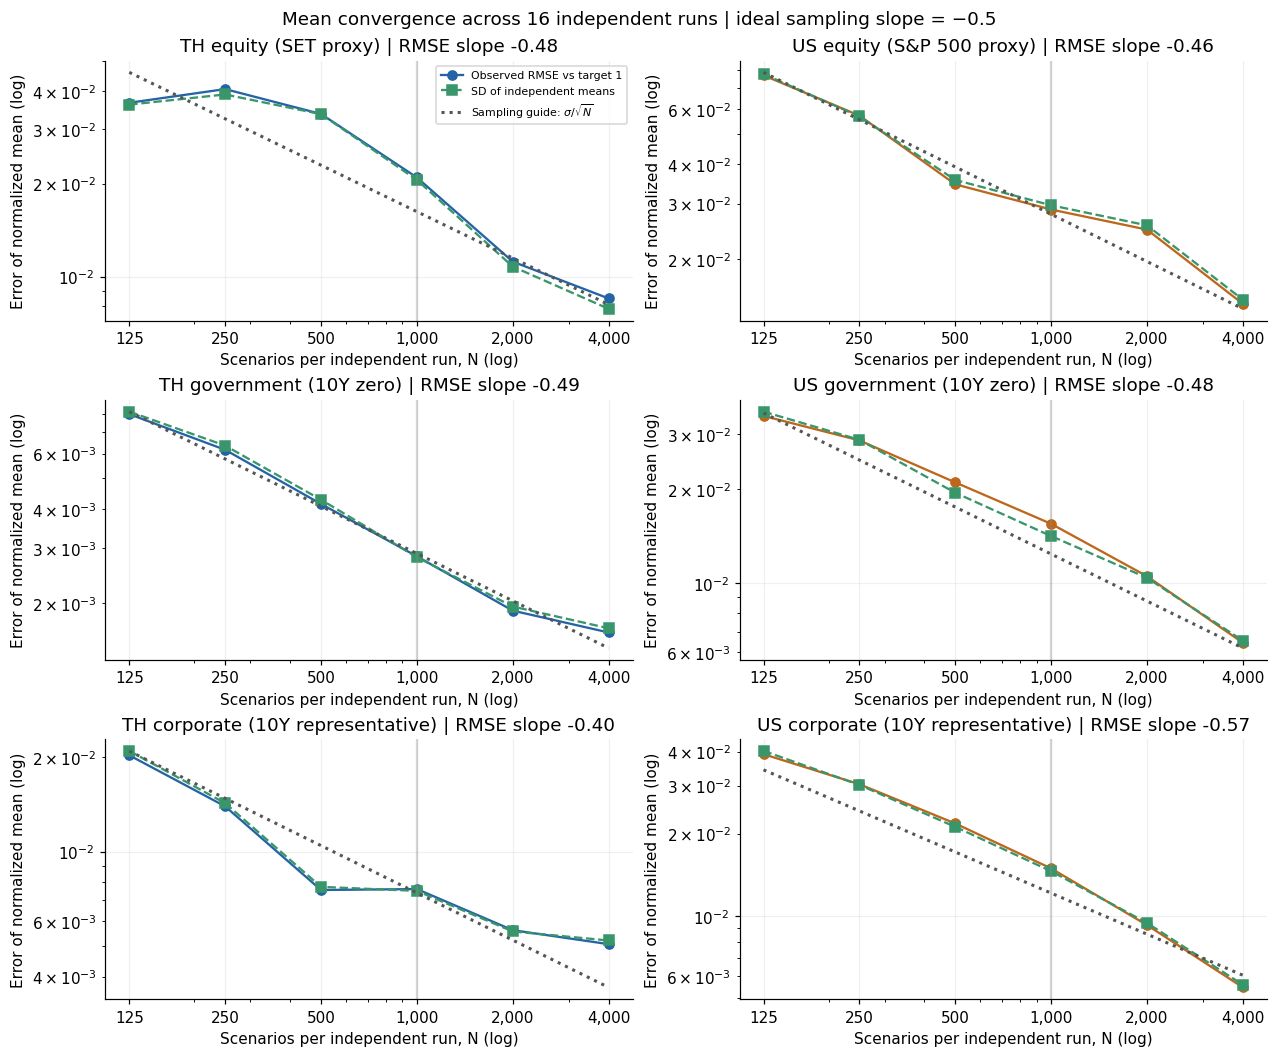

security,measured_RMSE_loglog_slope,ideal_sampling_slope,large_N_average_drift
TH equity (SET proxy),-0.479789,-0.5,0.003770
US equity (S&P 500 proxy),-0.455972,-0.5,0.000911
TH government (10Y zero),-0.491422,-0.5,-0.000089
US government (10Y zero),-0.481081,-0.5,-0.001152
TH corporate (10Y representative),-0.397552,-0.5,0.000520
US corporate (10Y representative),-0.568062,-0.5,-0.000771


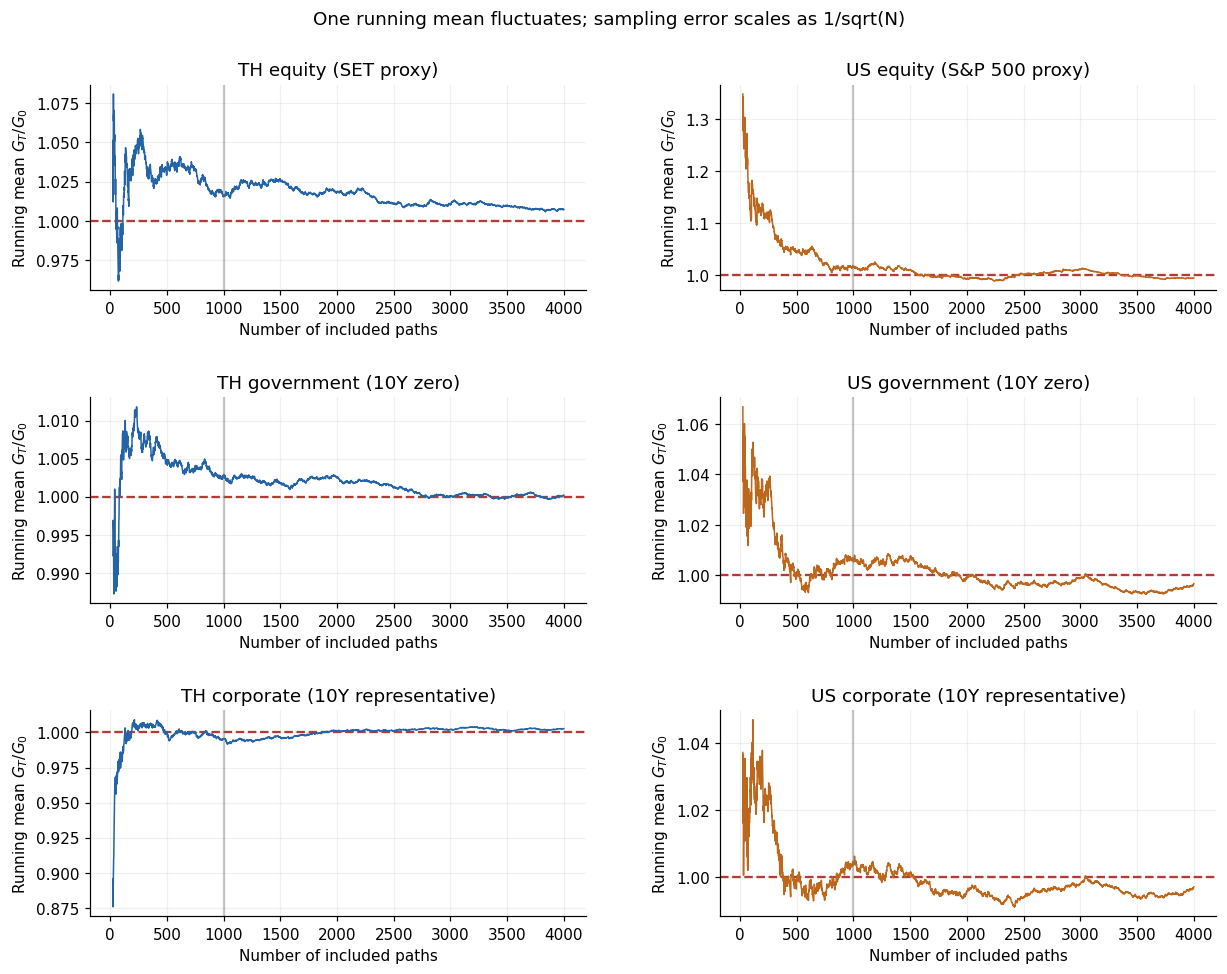

In [17]:
CONVERGENCE=mean_convergence(RUN['market'],sizes=(125,250,500,1000,2000,4000),replicates=16,horizon=10.,heston_scheme=RUN["settings"]["heston_scheme"])
show(convergence_figure(CONVERGENCE),'mean-convergence')
table(pd.DataFrame({'security':LABELS,'measured_RMSE_loglog_slope':CONVERGENCE['rmse_loglog_slopes'],
                    'ideal_sampling_slope':-.5,'large_N_average_drift':CONVERGENCE['large_N_average_drift']}))
show(running_means_figure(CONVERGENCE),'running-means')

## 6. Separate check for fixed-timestep bias in the six-security hybrid

More scenarios reduce sampling error, not model/discretization bias. Here the
same ten-year model is rerun at monthly, twice-monthly and weekly internal steps,
with 1,000 scenarios per run and four independent runs per setting. Reporting
remains monthly. Weekly grids include month-end reporting dates, so the actual
step count exceeds $52\times10$.

The table reports the terminal normalized cumulative gain mean (target 1) and
replicate uncertainty for each of the six securities. Different timestep grids do
not represent the same Brownian paths, even when seed labels coincide.

In [18]:
STEP_ROWS=[]
for frequency in (12,24,52):
    means=[]
    for r in range(4):
        p=simulate(RUN['market'],paths=1000,horizon=10.,seed=3001+101*r,internal_steps=frequency,
                       store_security_values=False,terminal_only=True,heston_scheme=RUN["settings"]["heston_scheme"])
        means.append((p.gains[-1]/p.gains[0]).mean(axis=0))
    means=np.array(means)
    for a,label in enumerate(LABELS):
        STEP_ROWS.append({'security':label,'nominal_steps_per_year':frequency,'actual_internal_steps':p.diagnostics['internal_steps'],
                         'replicates':4,'paths_per_run':1000,'terminal_mean_M':means[:,a].mean(),
                         'replicate_SE':means[:,a].std(ddof=1)/2})
table(pd.DataFrame(STEP_ROWS))

security,nominal_steps_per_year,actual_internal_steps,replicates,paths_per_run,terminal_mean_M,replicate_SE
TH equity (SET proxy),12,120,4,1000,0.998850,0.008970
US equity (S&P 500 proxy),12,120,4,1000,1.030498,0.011877
TH government (10Y zero),12,120,4,1000,0.998045,0.000350
US government (10Y zero),12,120,4,1000,1.008640,0.005844
TH corporate (10Y representative),12,120,4,1000,0.998371,0.001064
US corporate (10Y representative),12,120,4,1000,1.005766,0.006576
TH equity (SET proxy),24,240,4,1000,0.989890,0.012940
US equity (S&P 500 proxy),24,240,4,1000,1.027108,0.010821
TH government (10Y zero),24,240,4,1000,1.001072,0.001568
US government (10Y zero),24,240,4,1000,1.001702,0.006487


## 7. Export and interpretation

The export contains observed input points and provenance, the full parameter
manifest, mean ex-distribution prices, mean discounted cumulative gains and
their sampling errors, selected state paths, Heston comparison results, and
convergence tables. It does not contain insurance cash flows.

For a stronger conclusion, increase independent runs and refine timesteps. A
finite sample can cross a confidence band. A real input snapshot does not identify
all Heston/rate/credit dynamics. No risk-neutral path plot is a historical return
forecast or proof of production accuracy.

The ordinary figures above are deliberately independent of widgets. If the live
controls are unavailable, edit the small configuration cells and rerun them, or
open the [HTML copy](outputs/six_securities.html).

These notebook sections are the visual validation workflow; there is no separate test suite.


In [19]:
p=RUN['paths']
export={'metadata':metadata(RUN['market'],RUN['settings']), 'scope':'six security proxies only; no insurance liabilities',
        'data_source':RUN['source'],'data_provenance':DATA['manifest'],'mechanical_checks':structural_checks(p),
        'discount_checks':discount_checks(p,RUN['market']),'gain_diagnostics':gain_diagnostics(p),
        'heston_comparison':HESTON_PRICES,'timestep_check':STEP_ROWS,
        'convergence':{k:v for k,v in CONVERGENCE.items() if k not in ('replicate_means','running_means_first_run')}}
write_json(OUT/'inspection.json',export)
write_json(OUT/'parameters.json',asdict(RUN['market']))
pd.DataFrame(p.values.mean(axis=1),index=p.times,columns=LABELS).rename_axis('projection_year').to_csv(OUT/'mean-security-values.csv')
pd.DataFrame(p.gains.mean(axis=1),index=p.times,columns=LABELS).rename_axis('projection_year').to_csv(OUT/'mean-discounted-gains.csv')
pd.DataFrame(p.gains.std(axis=1,ddof=1)/np.sqrt(p.gains.shape[1]),index=p.times,columns=LABELS).rename_axis('projection_year').to_csv(OUT/'gain-mean-standard-errors.csv')
pd.DataFrame(HESTON_PRICES).to_csv(OUT/'heston-methods.csv',index=False)
pd.DataFrame([{'N':int(n),'security':LABELS[a],'RMSE':CONVERGENCE['rmse'][i,a],
              'SD_of_run_means':CONVERGENCE['empirical_SD_of_means'][i,a],
              'sigma_over_sqrt_N':CONVERGENCE['sigma_over_sqrt_N'][i,a]} for i,n in enumerate(CONVERGENCE['sizes']) for a in range(6)]).to_csv(OUT/'mean-convergence.csv',index=False)
print('Exported:',OUT)
print('Default six-security shape:',RUN['paths'].gains.shape)

Exported: /Users/yh/ESG_draft/outputs
Default six-security shape: (121, 1000, 6)
